# Bus crowding: when, on which routes, and where

BUSTO's "max demand hour" files give, for every route, direction, stop and time band, the stop's
**busiest hour**: passengers on board passing the stop in that hour (`hourload`), and the seats and
total space (seats + standing) of the buses passing in the same hour.

**Crowding measures** (for a route-stop in its busiest hour):

* **standing**: load above the seats offered, so on average some passengers stand;
* **near full**: load at least 80% of total capacity.

Only route-stop-hours with at least 150 places an hour (about two buses) are counted, so that
a few passengers on a single late bus do not register as crowding (see the EDA).

These are **typical-day averages** for the financial year: real crowding on individual buses is
higher and more variable. The measures are best read as where and when crowding is systematic.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

import tfl_bus as B

B.RESULTS.mkdir(parents=True, exist_ok=True)
con = B.busto_con()
q = lambda sql: con.execute(sql).df()
MIN_CAP = 150
TB = {1: 'early 05-07', 2: 'AM peak 07-10', 3: 'inter-peak 10-16', 4: 'PM peak 16-19',
      5: 'evening 19-22', 6: 'late 22-24', 7: 'night 00-05'}

# one row per year, day type, time band, route, direction, stop (a few duplicates from mixed route variants)
m = q('''SELECT year, day_type, timeband::INT AS tb, route, direction, stopcode,
                max(stopname) AS stopname, min(stopsequence) AS seq, max(qhr) AS hour_start,
                max(hourload) AS load, max(hourseats) AS seats, max(hourcapacity) AS cap
         FROM maxhr GROUP BY ALL''')
# Saturday and Sunday files number their bands 8-12 and 13-17: map onto the weekday bands
sat_sun = {8: 'early + AM 05-10', 9: 'day 10-19', 10: 'evening 19-22', 11: 'late 22-24', 12: 'night 00-05'}
m['band'] = np.where(m.tb <= 7, m.tb.map(TB), ((m.tb - 8) % 5 + 8).map(sat_sun))
m['ok'] = m['cap'] >= MIN_CAP
m['standing'] = m['ok'] & (m['load'] > m['seats'])
m['near_full'] = m['ok'] & (m['load'] >= 0.8 * m['cap'])
m['ratio'] = m['load'] / m['seats']
print(f"{len(m):,} route-stop-hours; {100 * (~m.ok).mean():.1f}% below {MIN_CAP} places/hour and not counted")

2,328,856 route-stop-hours; 18.6% below 150 places/hour and not counted


## 1. How common is crowding, and when?

In [2]:
def rates(g):
    ok = g[g.ok]
    return pd.Series({
        'route-stop-hours': len(ok),
        'standing (%)': 100 * ok.standing.mean(),
        'near full (%)': 100 * ok.near_full.mean(),
        'passengers on standing route-stops (%)': 100 * ok.load[ok.standing].sum() / ok.load.sum(),
    })

order = {'Weekday': list(TB.values()), 'Saturday': list(sat_sun.values()), 'Sunday': list(sat_sun.values())}
summary = m[m.year == 2025].groupby(['day_type', 'band']).apply(rates, include_groups=False)
summary = summary.reindex([(d, b) for d in B.DAY_TYPES for b in order[d] if (d, b) in summary.index]).round(4)
summary.to_csv(B.RESULTS / 'crowding_by_time_band.csv')
summary

route-stop-hours  standing (%)  near full (%)  \
day_type band                                                              
Weekday  early 05-07                41257.0        1.1877         0.0242   
         AM peak 07-10              38916.0        3.4485         0.0437   
         inter-peak 10-16           38727.0        1.4202         0.0129   
         PM peak 16-19              38678.0        1.3574         0.0362   
         evening 19-22              38554.0        0.0285         0.0000   
         late 22-24                 36150.0        0.0138         0.0055   
         night 00-05                34465.0        0.1132         0.0145   
Saturday early + AM 05-10           42064.0        0.1545         0.0095   
         day 10-19                  39176.0        0.2068         0.0153   
         evening 19-22              37622.0        0.0239         0.0000   
         late 22-24                 36262.0        0.0386         0.0083   
         night 00-05                35834.0        0.0642         0.0028   
Sunday   early + AM 05-10           38636.0        0.1682         0.0000   
         day 10-19                  36203.0        0.9226         0.0055   
         evening 19-22              35423.0        0.0085         0.0000   
         late 22-24                 35849.0        0.0781         0.0279   
         night 00-05                33031.0        0.1726         0.0575   

                           passengers on standing route-stops (%)  
day_type band                                                      
Weekday  early 05-07                                       2.5311  
         AM peak 07-10                                     5.1700  
         inter-peak 10-16                                  1.7194  
         PM peak 16-19                                     1.9620  
         evening 19-22                                     0.0788  
         late 22-24                                        0.0665  
         night 00-05                                       0.4523  
Saturday early + AM 05-10                                  0.3708  
         day 10-19                                         0.3154  
         evening 19-22                                     0.0719  
         late 22-24                                        0.1577  
         night 00-05                                       0.2828  
Sunday   early + AM 05-10                                  0.5611  
         day 10-19                                         1.6308  
         evening 19-22                                     0.0150  
         late 22-24                                        0.3438  
         night 00-05                                       1.7486

Crowding is concentrated in the **weekday morning peak**; at weekends it is rare. On the busiest
time band, about 3% of route-stops have standing in their busiest hour.

**Is it school travel?** The busiest hour of crowded route-stops, by quarter hour it starts:

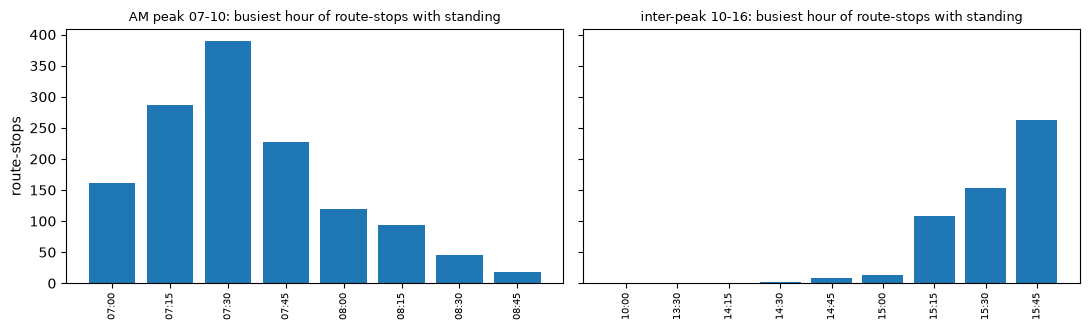

,value
AM peak: most common busiest-hour start of route-stops with standing,07:30
inter-peak: % of route-stops with standing whose busiest hour starts 14:30-15:45,99.4545


In [3]:
wk = m[(m.year == 2025) & (m.day_type == 'Weekday') & m.ok]
start = wk.assign(h=wk.hour_start.astype(str).str[:5])
crowded_start = start[start.standing].groupby(['band', 'h']).size()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, band in zip(axs, ['AM peak 07-10', 'inter-peak 10-16']):
    s = crowded_start.loc[band]
    ax.bar(s.index, s.values); ax.set_title(f'{band}: busiest hour of route-stops with standing', fontsize=9)
    ax.tick_params(axis='x', rotation=90, labelsize=7)
axs[0].set_ylabel('route-stops'); plt.tight_layout(); plt.show()
ip = start[(start.band == 'inter-peak 10-16') & start.standing]
timing = pd.Series({
    'AM peak: most common busiest-hour start of route-stops with standing': crowded_start.loc['AM peak 07-10'].idxmax(),
    'inter-peak: % of route-stops with standing whose busiest hour starts 14:30-15:45':
        round(100 * ip.h.between('14:30', '15:45').mean(), 4),
}, name='value')
timing.to_csv(B.RESULTS / 'crowding_timing.csv', index_label='measure')
timing.to_frame()

Standing in the inter-peak band almost all happens in the hour starting mid-afternoon, when schools
finish. Together with the morning peak on suburban routes, this points to **school travel** as a
large part of systematic bus crowding.

## 2. Which routes?

Weekday AM peak 2025-26. A route-direction's crowded stretch runs from the first to the last stop
with standing.

In [4]:
am = wk[wk.band == 'AM peak 07-10'].sort_values(['route', 'direction', 'seq'])

def stretch(g):
    s = g[g.standing]
    return pd.Series({
        'type': B.route_type(g.name[0]),
        'stops with standing': len(s), 'stops on route': len(g),
        'peak load / seats': g.ratio.max().round(2),
        'peak hourly load': g.load.max().round(0),
        'crowded from': s.stopname.iloc[0].title() if len(s) else '',
        'to': s.stopname.iloc[-1].title() if len(s) else '',
        'busiest hour': str(g.loc[g.load.idxmax(), 'hour_start'])[:5],
    })

routes = am.groupby(['route', 'direction']).apply(stretch, include_groups=False)
routes = routes.sort_values(['stops with standing', 'peak load / seats'], ascending=False)
routes[routes['stops with standing'] > 0].to_csv(B.RESULTS / 'crowded_routes_am_peak.csv')
print(f"{(routes['stops with standing'] > 0).sum()} of {len(routes)} route-directions have standing somewhere in the AM peak")
routes.head(15)

185 of 1000 route-directions have standing somewhere in the AM peak


,,type,stops with standing,stops on route,peak load / seats,peak hourly load,crowded from,to,busiest hour
route,direction,,,,,,,,
493,1,numbered,40,63,1.41,176.0,Wimbledon Road,Kings Road,08:30
117,2,numbered,33,50,1.69,159.0,Chattern Hill,Grainger Road,07:00
152,1,numbered,24,46,1.39,201.0,Meopham Road / Woodstock Way,Raynes Park Library,07:00
117,1,numbered,24,53,1.25,101.0,Carlton Avenue,Edinburgh Drive,07:30
493,2,numbered,23,55,1.43,191.0,Medfield Street,Wimbledon Stadium,07:15
K1,1,letter prefix,21,38,1.47,156.0,New Malden / The Fountain,Surbiton Sainsbury'S,07:30
W19,2,letter prefix,20,44,1.53,227.0,First Avenue,Clare Road,08:00
167,1,numbered,20,30,1.44,115.0,Valentines Park,Brook Way,07:00
E10,1,letter prefix,17,32,1.74,131.0,Marley Close,Charlbury Grove,07:45


In [5]:
by_type = routes.groupby('type').agg(route_directions=('stops on route', 'size'),
                                     with_standing=('stops with standing', lambda s: (s > 0).sum()),
                                     standing_stops=('stops with standing', 'sum'),
                                     all_stops=('stops on route', 'sum'))
by_type['standing stops (%)'] = (100 * by_type.standing_stops / by_type.all_stops).round(2)
by_type

,route_directions,with_standing,standing_stops,all_stops,standing stops (%)
type,,,,,
letter prefix,156,51,358,4992,7.17
numbered,825,129,965,33605,2.87
superloop,19,5,19,319,5.96


## 3. Where? Crowding and distance from rail

In [6]:
linked = pd.read_parquet(B.PROCESSED / 'bus-stops-linked.parquet')
a = am.join(linked[['dist_m', 'lat', 'lon']], on='stopcode').dropna(subset=['dist_m'])
a['to_rail'] = pd.cut(a.dist_m, [0, 400, 800, 2000, np.inf], right=False,
                      labels=['< 400 m', '400-800 m', '800 m - 2 km', '> 2 km'])
a['from_centre'] = pd.cut(B.haversine_m(a.lat, a.lon, 51.5080, -0.1246) / 1000, [0, 3, 6, 10, 15, 50],
                          labels=['0-3 km', '3-6 km', '6-10 km', '10-15 km', '15+ km'])
tab = pd.concat({
    'to_rail': a.groupby('to_rail', observed=True).agg(route_stops=('standing', 'size'), standing_pct=('standing', 'mean')),
    'from_centre': a.groupby('from_centre', observed=True).agg(route_stops=('standing', 'size'), standing_pct=('standing', 'mean')),
})
tab['standing_pct'] = (100 * tab['standing_pct']).round(4)
tab.to_csv(B.RESULTS / 'crowding_by_location.csv')
tab

route_stops  standing_pct
to_rail     < 400 m             10874        1.7197
            400-800 m            8678        2.8578
            800 m - 2 km        10470        4.2025
            > 2 km               8254        5.0642
from_centre 0-3 km               2187        2.5149
            3-6 km               4551        1.6480
            6-10 km              7775        1.5434
            10-15 km            10521        4.2486
            15+ km              13242        4.5008

Outer London and stops far from rail are both more crowded, and the two overlap. A linear
probability model separates them (AM peak route-stops; standard errors clustered by route):

In [7]:
a['standing_i'] = a.standing.astype(int) * 100
a['to_rail_s'] = a.to_rail.astype(str)
a['ring'] = a.from_centre.astype(str)
lpm = smf.ols("standing_i ~ C(to_rail_s, Treatment('< 400 m')) + C(ring, Treatment('0-3 km'))", data=a).fit(
    cov_type='cluster', cov_kwds={'groups': pd.factorize(a.route)[0]})
coef = pd.DataFrame({'percentage points': lpm.params, 'ci_low': lpm.conf_int()[0], 'ci_high': lpm.conf_int()[1]})
coef.index = coef.index.str.replace(r"C\((\w+), Treatment\('[^']+'\)\)\[T\.", r'\1: ', regex=True).str.rstrip(']')
coef.round(4).to_csv(B.RESULTS / 'crowding_location_model.csv', index_label='term')
coef.round(2)

,percentage points,ci_low,ci_high
Intercept,2.30,0.96,3.64
to_rail_s: 400-800 m,1.05,0.59,1.51
to_rail_s: 800 m - 2 km,2.08,1.13,3.03
to_rail_s: > 2 km,2.50,0.82,4.17
ring: 10-15 km,0.52,-1.35,2.38
ring: 15+ km,0.33,-1.65,2.30
ring: 3-6 km,-1.32,-2.63,-0.01
ring: 6-10 km,-1.81,-3.52,-0.11


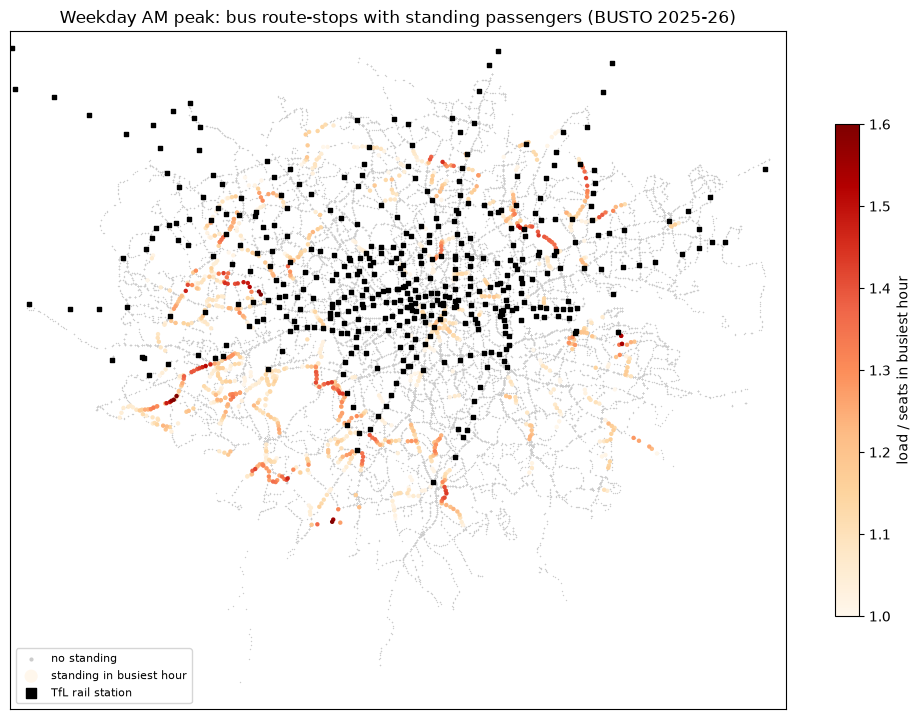

In [8]:
fig, ax = plt.subplots(figsize=(10, 8.5))
calm = a[~a.standing]
ax.scatter(calm.lon, calm.lat, s=1, color='#cccccc', lw=0, label='no standing')
hot = a[a.standing].sort_values('ratio')
sc = ax.scatter(hot.lon, hot.lat, c=hot.ratio.clip(upper=1.6), cmap='OrRd', vmin=1, vmax=1.6, s=10, lw=0,
                label='standing in busiest hour')
rail = B.rail_stations()
ax.scatter(rail.lon, rail.lat, s=5, color='black', marker='s', label='TfL rail station')
ax.set_aspect(1 / np.cos(np.radians(51.5))); ax.set_xticks([]); ax.set_yticks([])
ax.set_xlim(a.lon.min() - .02, a.lon.max() + .02); ax.set_ylim(a.lat.min() - .02, a.lat.max() + .02)
plt.colorbar(sc, ax=ax, shrink=.6, label='load / seats in busiest hour')
ax.legend(loc='lower left', fontsize=8, markerscale=3)
ax.set_title('Weekday AM peak: bus route-stops with standing passengers (BUSTO 2025-26)')
plt.tight_layout(); plt.show()

## 4. Has crowding changed since 2023-24?

In [9]:
trend = (m[m.ok & (m.day_type == 'Weekday') & m.band.isin(['AM peak 07-10', 'inter-peak 10-16', 'PM peak 16-19'])]
         .groupby(['band', 'year'])[['standing', 'near_full']].mean().mul(100).round(4).unstack('year'))
trend.to_csv(B.RESULTS / 'crowding_by_year.csv')
trend

standing                 near_full                
year                 2023    2024    2025      2023    2024    2025
band                                                               
AM peak 07-10      2.8497  3.3243  3.4485    0.0078  0.0359  0.0437
PM peak 16-19      1.0532  1.3022  1.3574    0.0105  0.0206  0.0362
inter-peak 10-16   1.5018  1.7584  1.4202    0.0000  0.0000  0.0129

In [10]:
# Route level: did routes whose AM-peak capacity was cut become more crowded?
am_all = m[(m.day_type == 'Weekday') & (m.band == 'AM peak 07-10') & m.year.isin([2023, 2025])]
rt = am_all.groupby(['route', 'year']).agg(cap=('cap', 'sum'), load=('load', 'sum'),
                                           standing=('standing', 'mean')).unstack('year').dropna()
rt.columns = [f'{v}_{y}' for v, y in rt.columns]
rt['d_cap'] = 100 * (rt['cap_2025'] / rt['cap_2023'] - 1)
rt['d_load'] = 100 * (rt['load_2025'] / rt['load_2023'] - 1)
rt['d_standing_pp'] = 100 * (rt['standing_2025'] - rt['standing_2023'])
rt['capacity'] = pd.cut(rt.d_cap, [-np.inf, -10, -2, 2, 10, np.inf],
                        labels=['cut > 10%', 'cut 2-10%', 'about the same', 'up 2-10%', 'up > 10%'])
change = rt.groupby('capacity', observed=True).agg(routes=('d_cap', 'size'), load_change_pct=('d_load', 'median'),
                                                    standing_change_pp=('d_standing_pp', 'mean')).round(4)
change.to_csv(B.RESULTS / 'crowding_change_by_capacity.csv')
change

,routes,load_change_pct,standing_change_pp
capacity,,,
cut > 10%,100,-13.5601,1.4320
cut 2-10%,187,-2.7943,0.6358
about the same,123,0.0453,-0.0762
up 2-10%,86,3.4638,0.5665
up > 10%,47,15.3193,-0.5591


## Summary

* **Crowding is a weekday morning problem.** In 2025-26, 3.4% of route-stops have standing in their
  busiest AM-peak hour (5% of AM-peak passengers are on those route-stops), against about 1.4% in the
  inter-peak and PM peak and almost none in the evening or at weekends. Load reaching 80% of total
  capacity is very rare (0.04%): in the averages, buses fill their seats but are seldom packed.
* **School travel drives much of it.** AM-peak crowding peaks in the hour from 07:30, and 99% of
  inter-peak crowding is in the hour starting 15:15-15:45, just after schools finish.
* **It is on suburban routes, away from rail.** 185 of 1,000 route-directions have standing somewhere in
  the AM peak; the most crowded (493, 117, 152, K1, W19, 167, E10) are outer-London routes. Stops more than
  800 m from TfL rail are 2-2.5 percentage points more likely to have standing than stops near rail, even
  after allowing for distance from the centre (1.7% within 400 m, 5.1% beyond 2 km). Buses are most
  crowded where they are the main public transport.
* **Crowding has risen as service was cut.** AM-peak standing rose from 2.8% of route-stops in 2023-24 to
  3.4% in 2025-26, while passengers fell. Routes whose AM capacity was cut by more than 10% lost 14% of
  their passengers but still became more crowded (+1.4 points); routes with more capacity gained
  passengers and became less crowded.